In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor,ExtraTreesRegressor
from xgboost import XGBRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error
import pickle
import warnings
warnings.filterwarnings("ignore")


In [29]:
dataset= pd.read_csv ("cleaned_train_data.csv")


In [30]:
X = dataset.drop('Price',axis=1)
y = dataset['Price']

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [32]:
#Linear Regression

step1 = ColumnTransformer(transformers=[
    ('col_1',OneHotEncoder(sparse_output=False,drop='first',handle_unknown='ignore'),[0,3,4,10]),
    ('col_2',OrdinalEncoder(),[5])
],remainder='passthrough')

step2 = LinearRegression()

pipe = Pipeline([
    ('step1',step1),
    ('ss',StandardScaler()),
    ('step2',step2)
])

pipe.fit(X_train,y_train)
y_pred = pipe.predict(X_test)

print('R2 Score : ', r2_score(y_test,y_pred))
print('MAE : ', mean_absolute_error(y_test,y_pred))

R2 Score :  0.7459854661803282
MAE :  3.1733631256043875


In [33]:
#Random Forest Regressor

step1 = ColumnTransformer(transformers=[
    ('col_1',OneHotEncoder(sparse_output=False,drop='first',handle_unknown='ignore'),[0,3,4,10]),
    ('col_2',OrdinalEncoder(),[5])
],remainder='passthrough')

step2 = RandomForestRegressor(max_depth=19,
                             n_estimators=100,
                             random_state=3,
                             max_samples=0.5,
                             max_features=0.75)

pipe = Pipeline([
    ('step1',step1),
    ('step2',step2)
])

pipe.fit(X_train,y_train)
y_pred = pipe.predict(X_test)

print('R2 Score : ', r2_score(y_test,y_pred))
print('MAE : ', mean_absolute_error(y_test,y_pred))

R2 Score :  0.855898094877191
MAE :  1.6215177059642436


In [34]:
#XGB Regressor

step1 = ColumnTransformer(transformers=[
    ('col_1',OneHotEncoder(sparse_output=False,drop='first',handle_unknown='ignore'),[0,3,4,10]),
    ('col_2',OrdinalEncoder(),[5])
],remainder='passthrough')

step2 = XGBRegressor(n_estimators=500,max_depth=25,learning_rate=0.25)

pipe = Pipeline([
    ('step1',step1),
    ('step2',step2)
])

pipe.fit(X_train,y_train)
y_pred = pipe.predict(X_test)

print('R2 Score : ', r2_score(y_test,y_pred))
print('MAE : ', mean_absolute_error(y_test,y_pred))

R2 Score :  0.8547326720894797
MAE :  1.6691592146233876


In [35]:
#Stacking Regressor

step1 = ColumnTransformer(transformers=[
    ('col_1',OneHotEncoder(sparse_output=False,drop='first',handle_unknown='ignore'),[0,3,4,10]),
    ('col_2',OrdinalEncoder(),[5])
],remainder='passthrough')

estimators = [
    ('rf', RandomForestRegressor(n_estimators=350,random_state=3,max_features=0.75,max_depth=25)),
    ('gbdt',GradientBoostingRegressor(n_estimators=1000,max_features=0.5)),
    ('xgb', XGBRegressor(n_estimators=100,learning_rate=0.25,max_depth=15))
]

step2 = StackingRegressor(estimators=estimators, final_estimator= ExtraTreesRegressor(n_estimators=100,random_state=3,max_features=0.75,max_depth=10))

pipe = Pipeline([
    ('step1',step1),
    ('step2',step2)
])

pipe.fit(X_train,y_train)

y_pred = pipe.predict(X_test)

print('R2 score',r2_score(y_test,y_pred))
print('MAE',mean_absolute_error(y_test,y_pred))

R2 score 0.9053100586536558
MAE 1.4330002643474198


In [36]:
#Exporting model

pickle.dump(dataset,open('train.pkl','wb'))
pickle.dump(pipe,open('pipe.pkl','wb'))

In [37]:
# Model Comparison
model_r2_scores = {}
trained_pipelines = {}

def evaluate_model(name, step2_model, needs_scaling=False):
    step1 = ColumnTransformer(transformers=[
        ('col_tnf1', OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore'), [0, 3, 4, 10]),
        ('col_tnf2', OrdinalEncoder(), [5])
    ], remainder='passthrough')

    if needs_scaling:
        pipe = Pipeline([
            ('step1', step1),
            ('ss', StandardScaler()),
            ('step2', step2_model)
        ])
    else:
        pipe = Pipeline([
            ('step1', step1),
            ('step2', step2_model)
        ])

    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)


    model_r2_scores[name] = {'R2 Score': r2, 'MAE': mae}
    trained_pipelines[name] = pipe

# تقييم الأربعة موديلات
evaluate_model('Linear Regression', LinearRegression(), needs_scaling=True)
evaluate_model('Random Forest', RandomForestRegressor(max_depth=19, n_estimators=100, random_state=3), needs_scaling=False)
evaluate_model('XGBoost', XGBRegressor(n_estimators=500, max_depth=25, learning_rate=0.25), needs_scaling=False)

est_stack = [
    ('rf', RandomForestRegressor(n_estimators=350, random_state=3, max_features=0.75, max_depth=25)),
    ('xgb', XGBRegressor(n_estimators=100, learning_rate=0.25, max_depth=15))
]
evaluate_model('Stacking Regressor', StackingRegressor(estimators=est_stack, final_estimator=RandomForestRegressor(n_estimators=100, random_state=3)), needs_scaling=False)

# Display results
model_comparison_df = pd.DataFrame.from_dict(model_r2_scores, orient='index')
model_comparison_df = model_comparison_df.sort_values(by='R2 Score', ascending=False)
display(model_comparison_df)

# اختيار أفضل موديل تلقائياً وحفظه
best_model_name = max(model_r2_scores, key=lambda k: model_r2_scores[k]['R2 Score'])
best_pipeline = trained_pipelines[best_model_name]

print(f"\nThe best model is: {best_model_name} with R2 score = {model_r2_scores[best_model_name]['R2 Score']:.4f}")

pickle.dump(best_pipeline, open('pipe.pkl', 'wb'))
print("Best pipeline saved in: 'pipe.pkl'")

pickle.dump(dataset, open('train.pkl', 'wb'))

,R2 Score,MAE
Stacking Regressor,0.865615,1.754781
XGBoost,0.854733,1.669159
Random Forest,0.854470,1.576772
Linear Regression,0.745985,3.173363



The best model is: Stacking Regressor with R2 score = 0.8656
Best pipeline saved in: 'pipe.pkl'


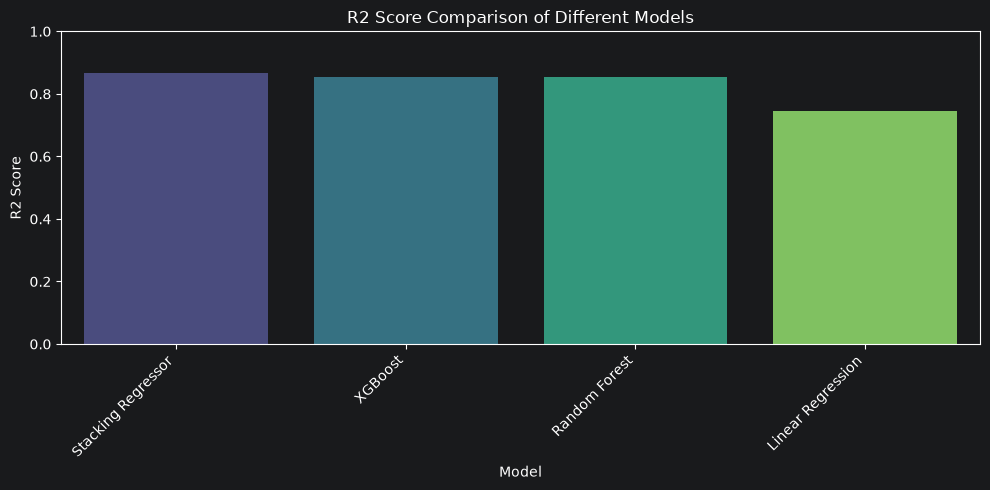

In [38]:
plt.figure(figsize=(10, 5))
sns.barplot(x=model_comparison_df.index, y='R2 Score', data=model_comparison_df, palette='viridis')
plt.xlabel('Model')
plt.ylabel('R2 Score')
plt.title('R2 Score Comparison of Different Models')
plt.xticks(rotation=45, ha='right')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()